# Single-prompt semantic topology

This notebook captures the representation of every prompt token at every layer of Pythia 6.9B, then analyzes the target token ` lithium`. It performs no text generation.

The outputs distinguish static input-embedding neighbours, contextual layer-wise relationships, and the final next-token distribution. These are different measurements and must not be treated as interchangeable notions of meaning.

## 1. Configuration and run registration

The target concept is placed at the end because Pythia is causal: its representation can then incorporate the entire preceding prompt. This cell validates the shared model cache and available GPU memory before creating a run directory.

In [1]:
from importlib.util import find_spec

required_packages = [
    "torch",
    "transformers",
    "safetensors",
    "pandas",
    "matplotlib",
    "packaging",
]
missing_packages = [name for name in required_packages if find_spec(name) is None]
if missing_packages:
    raise RuntimeError(
        f"Missing packages: {', '.join(missing_packages)}. "
        "Install the project notebook dependencies and restart the kernel."
    )

import gc
import hashlib
import json
import os
import platform
import re
import time
from datetime import datetime, timezone
from pathlib import Path

import matplotlib
import matplotlib.pyplot as plt
import pandas as pd
import safetensors
import torch
import torch.nn.functional as F
import transformers
from IPython.display import display
from packaging.version import Version
from safetensors.torch import load_file, save_file
from transformers import AutoModelForCausalLM, AutoTokenizer

RUN_NUMBER = "R001"
RUN_NAME = "lithium-initial-output-inspection"
MODEL_ID = "EleutherAI/pythia-6.9b"
MODEL_REVISION = "c0e3eee36dc47af0c49f361c74cfe459c09f7f23"
PROMPT = (
    "Battery demand, mineral supply, electric vehicles, and energy storage "
    "all shape the market for lithium"
)
TARGET_TEXT = " lithium"
SEED = 42
STATIC_NEIGHBOR_COUNT = 20
PREDICTION_COUNT = 20
MINIMUM_FREE_GPU_GIB = 14.0

current_directory = Path.cwd().resolve()
PIPELINE_DIR = (
    current_directory
    if current_directory.name == "single_prompt_topology"
    else current_directory / "single_prompt_topology"
)
if not PIPELINE_DIR.is_dir():
    raise RuntimeError(
        f"Cannot locate the pipeline directory from {current_directory}. "
        "Launch JupyterLab from the llm_topology project or this pipeline directory."
    )
RUNS_DIR = PIPELINE_DIR / "runs"
RUNS_DIR.mkdir(parents=True, exist_ok=True)

if not re.fullmatch(r"R\d{3}", RUN_NUMBER):
    raise ValueError("RUN_NUMBER must use the form RNNN, for example R002.")
if not re.fullmatch(r"[a-z0-9]+(?:-[a-z0-9]+)*", RUN_NAME):
    raise ValueError("RUN_NAME must use neutral lowercase kebab-case.")
existing_run_numbers = sorted(path.name for path in RUNS_DIR.glob(f"{RUN_NUMBER}_*"))
if existing_run_numbers:
    raise RuntimeError(
        f"{RUN_NUMBER} is already assigned to {existing_run_numbers[0]}. "
        "Choose the next unused run number before executing the notebook."
    )

EXPECTED_HF_HOME = Path(r"D:\AI\cache\huggingface").resolve()
EXPECTED_HF_HUB_CACHE = (EXPECTED_HF_HOME / "hub").resolve()
hf_home_value = os.environ.get("HF_HOME")
hf_hub_cache_value = os.environ.get("HF_HUB_CACHE")
if not hf_home_value or not hf_hub_cache_value:
    raise RuntimeError("HF_HOME and HF_HUB_CACHE must be configured before model loading.")
if Path(hf_home_value).resolve() != EXPECTED_HF_HOME:
    raise RuntimeError(f"HF_HOME must resolve to {EXPECTED_HF_HOME}.")
if Path(hf_hub_cache_value).resolve() != EXPECTED_HF_HUB_CACHE:
    raise RuntimeError(f"HF_HUB_CACHE must resolve to {EXPECTED_HF_HUB_CACHE}.")
MODEL_CACHE_DIR = EXPECTED_HF_HUB_CACHE

if not torch.cuda.is_available():
    raise RuntimeError("This proof of concept requires a CUDA GPU.")
DEVICE = torch.device("cuda")
MODEL_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16
free_bytes, total_bytes = torch.cuda.mem_get_info()
free_gpu_gib = free_bytes / 1024**3
total_gpu_gib = total_bytes / 1024**3
if free_gpu_gib < MINIMUM_FREE_GPU_GIB:
    raise RuntimeError(
        f"Only {free_gpu_gib:.2f} GiB of {total_gpu_gib:.2f} GiB GPU memory is free. "
        "Shut down the kernel holding Pythia 12B and rerun this cell."
    )

started_at = datetime.now(timezone.utc)
prompt_sha256 = hashlib.sha256(PROMPT.encode("utf-8")).hexdigest()
model_slug = MODEL_ID.rsplit("/", 1)[-1]
technical_id = f"{started_at.strftime('%Y%m%dT%H%M%SZ')}_{model_slug}_{prompt_sha256[:10]}"
run_id = f"{RUN_NUMBER}_{RUN_NAME}__{technical_id}"
RUN_DIR = RUNS_DIR / run_id
FIGURES_DIR = RUN_DIR / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=False)
MANIFEST_PATH = RUN_DIR / "manifest.json"
TOKENS_PATH = RUN_DIR / "tokens.csv"
HIDDEN_STATES_PATH = RUN_DIR / "hidden_states.safetensors"
LAYER_METRICS_PATH = RUN_DIR / "layer_metrics.csv"
TARGET_RELATIONSHIPS_PATH = RUN_DIR / "target_relationships.csv"
SEMANTIC_NEIGHBORS_PATH = RUN_DIR / "semantic_neighbors.csv"

def utc_now_iso():
    return datetime.now(timezone.utc).isoformat()

def sha256_file(path: Path) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for block in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

manifest = {
    "run_number": RUN_NUMBER,
    "run_name": RUN_NAME,
    "run_id": run_id,
    "technical_id": technical_id,
    "source_run": None,
    "status": "running",
    "started_at": started_at.isoformat(),
    "completed_at": None,
    "required_components": ["capture", "analysis"],
    "components": {
        "capture": {"status": "pending"},
        "analysis": {"status": "pending"},
    },
    "model": {
        "id": MODEL_ID,
        "requested_revision": MODEL_REVISION,
        "resolved_revision": None,
        "dtype": str(MODEL_DTYPE),
    },
    "input": {
        "prompt": PROMPT,
        "prompt_sha256": prompt_sha256,
        "target_text": TARGET_TEXT,
        "seed": SEED,
    },
    "environment": {
        "python": platform.python_version(),
        "torch": torch.__version__,
        "transformers": transformers.__version__,
        "safetensors": safetensors.__version__,
        "pandas": pd.__version__,
        "matplotlib": matplotlib.__version__,
        "device": torch.cuda.get_device_name(0),
        "total_gpu_gib": round(total_gpu_gib, 3),
        "free_gpu_gib_before_load": round(free_gpu_gib, 3),
        "hf_home": str(EXPECTED_HF_HOME),
        "hf_hub_cache": str(EXPECTED_HF_HUB_CACHE),
    },
    "artifacts": {},
}

def write_manifest():
    MANIFEST_PATH.write_text(
        json.dumps(manifest, indent=2, ensure_ascii=False),
        encoding="utf-8",
    )

def mark_failed(component: str, error: Exception):
    manifest["status"] = "failed"
    manifest["completed_at"] = utc_now_iso()
    manifest["components"][component] = {
        "status": "failed",
        "error_type": type(error).__name__,
        "error": str(error),
    }
    write_manifest()

write_manifest()
print(f"Run:             {run_id}")
print(f"Output:          {RUN_DIR}")
print(f"Model:           {MODEL_ID}")
print(f"Revision:        {MODEL_REVISION}")
print(f"GPU memory free: {free_gpu_gib:.2f} / {total_gpu_gib:.2f} GiB")
print(f"Prompt:          {PROMPT}")
print(f"Target text:     {TARGET_TEXT!r}")

Run:             R001_lithium-initial-output-inspection__20261112T063540Z_pythia-6.9b_52ff8f97c2
Output:          D:\Sync\Python Projects\llm_topology\single_prompt_topology\runs\R001_lithium-initial-output-inspection__20261112T063540Z_pythia-6.9b_52ff8f97c2
Model:           EleutherAI/pythia-6.9b
Revision:        c0e3eee36dc47af0c49f361c74cfe459c09f7f23
GPU memory free: 22.50 / 23.99 GiB
Prompt:          Battery demand, mineral supply, electric vehicles, and energy storage all shape the market for lithium
Target text:     ' lithium'


## 2. Capture and save the measurements

This cell validates that the target is a single final token, captures the initial embedding output plus every transformer-layer output, saves the raw states, records static input-embedding neighbours and records the final next-token distribution. The model is then removed from GPU memory.

In [2]:
capture_started = time.perf_counter()
try:
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    tokenizer = AutoTokenizer.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        cache_dir=str(MODEL_CACHE_DIR),
    )
    encoded = tokenizer(PROMPT, return_tensors="pt", add_special_tokens=False)
    prompt_token_ids = encoded["input_ids"][0].tolist()
    target_token_ids = tokenizer(
        TARGET_TEXT,
        add_special_tokens=False,
    )["input_ids"]
    if len(target_token_ids) != 1:
        raise ValueError(
            f"TARGET_TEXT must encode to one token, but {TARGET_TEXT!r} encoded to "
            f"{target_token_ids}."
        )
    target_token_id = int(target_token_ids[0])
    if not prompt_token_ids or prompt_token_ids[-1] != target_token_id:
        raise ValueError(
            "The target token must be the final prompt token so it can attend to the full prefix."
        )
    target_position = len(prompt_token_ids) - 1

    token_rows = []
    for position, token_id in enumerate(prompt_token_ids):
        token_rows.append(
            {
                "position": position,
                "token_id": int(token_id),
                "raw_token": tokenizer.convert_ids_to_tokens(int(token_id)),
                "decoded_token": tokenizer.decode(
                    [int(token_id)],
                    clean_up_tokenization_spaces=False,
                ),
                "is_target": position == target_position,
            }
        )
    token_table = pd.DataFrame(token_rows)
    token_table.to_csv(TOKENS_PATH, index=False, encoding="utf-8")

    dtype_argument = (
        {"dtype": MODEL_DTYPE}
        if Version(transformers.__version__) >= Version("5.0.0")
        else {"torch_dtype": MODEL_DTYPE}
    )
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        revision=MODEL_REVISION,
        cache_dir=str(MODEL_CACHE_DIR),
        use_safetensors=True,
        **dtype_argument,
    ).to(DEVICE)
    model.eval()
    resolved_revision = getattr(model.config, "_commit_hash", MODEL_REVISION)
    encoded = {name: tensor.to(DEVICE) for name, tensor in encoded.items()}

    torch.cuda.reset_peak_memory_stats()
    torch.cuda.synchronize()
    forward_started = time.perf_counter()
    with torch.inference_mode():
        outputs = model(
            **encoded,
            output_hidden_states=True,
            use_cache=False,
            return_dict=True,
        )
    torch.cuda.synchronize()
    forward_seconds = time.perf_counter() - forward_started
    peak_gpu_memory_gib = torch.cuda.max_memory_allocated() / 1024**3

    hidden_states = torch.stack(
        [state[0].detach().to("cpu").contiguous() for state in outputs.hidden_states],
        dim=0,
    )
    expected_layer_count = int(model.config.num_hidden_layers) + 1
    if hidden_states.shape[0] != expected_layer_count:
        raise RuntimeError(
            f"Expected {expected_layer_count} saved states, got {hidden_states.shape[0]}."
        )
    if not torch.isfinite(hidden_states.float()).all():
        raise RuntimeError("Captured hidden states contain NaN or infinite values.")
    save_file(
        {"hidden_states": hidden_states},
        HIDDEN_STATES_PATH,
        metadata={
            "model_id": MODEL_ID,
            "resolved_revision": str(resolved_revision),
            "prompt_sha256": prompt_sha256,
            "target_text": TARGET_TEXT,
        },
    )

    embedding_weight = model.get_input_embeddings().weight.detach()
    target_embedding = F.normalize(
        embedding_weight[target_token_id].float(),
        dim=0,
    )
    similarity_chunks = []
    chunk_size = 4096
    for start in range(0, embedding_weight.shape[0], chunk_size):
        chunk = embedding_weight[start : start + chunk_size].float()
        chunk = F.normalize(chunk, dim=1)
        similarity_chunks.append((chunk @ target_embedding).to("cpu"))
    input_similarities = torch.cat(similarity_chunks)
    input_similarities[target_token_id] = -torch.inf
    neighbor_scores, neighbor_ids = torch.topk(
        input_similarities,
        k=STATIC_NEIGHBOR_COUNT,
    )

    final_probabilities = torch.softmax(
        outputs.logits[0, -1].detach().float(),
        dim=0,
    ).to("cpu")
    prediction_scores, prediction_ids = torch.topk(
        final_probabilities,
        k=PREDICTION_COUNT,
    )

    semantic_rows = []
    for rank, (token_id, score) in enumerate(
        zip(neighbor_ids.tolist(), neighbor_scores.tolist()),
        start=1,
    ):
        semantic_rows.append(
            {
                "source": "input_embedding",
                "metric": "cosine_similarity",
                "rank": rank,
                "token_id": int(token_id),
                "raw_token": tokenizer.convert_ids_to_tokens(int(token_id)),
                "decoded_token": tokenizer.decode(
                    [int(token_id)],
                    clean_up_tokenization_spaces=False,
                ),
                "score": float(score),
            }
        )
    for rank, (token_id, score) in enumerate(
        zip(prediction_ids.tolist(), prediction_scores.tolist()),
        start=1,
    ):
        semantic_rows.append(
            {
                "source": "final_prediction",
                "metric": "probability",
                "rank": rank,
                "token_id": int(token_id),
                "raw_token": tokenizer.convert_ids_to_tokens(int(token_id)),
                "decoded_token": tokenizer.decode(
                    [int(token_id)],
                    clean_up_tokenization_spaces=False,
                ),
                "score": float(score),
            }
        )
    semantic_neighbors = pd.DataFrame(semantic_rows)
    semantic_neighbors.to_csv(
        SEMANTIC_NEIGHBORS_PATH,
        index=False,
        encoding="utf-8",
    )

    manifest["model"]["resolved_revision"] = str(resolved_revision)
    manifest["input"]["token_ids"] = [int(value) for value in prompt_token_ids]
    manifest["input"]["target_token_id"] = target_token_id
    manifest["input"]["target_position"] = target_position
    manifest["capture"] = {
        "hidden_state_shape": list(hidden_states.shape),
        "hidden_state_dtype": str(hidden_states.dtype),
        "forward_seconds": forward_seconds,
        "peak_gpu_memory_gib": peak_gpu_memory_gib,
    }
    manifest["components"]["capture"] = {
        "status": "successful",
        "completed_at": utc_now_iso(),
    }
    write_manifest()

    print(f"Resolved revision: {resolved_revision}")
    print(f"Target token:      {target_token_id} at position {target_position}")
    print(f"Hidden states:     {tuple(hidden_states.shape)} {hidden_states.dtype}")
    print(f"Forward pass:      {forward_seconds:.3f} seconds")
    print(f"Peak GPU memory:   {peak_gpu_memory_gib:.2f} GiB")
    print(f"Capture elapsed:   {time.perf_counter() - capture_started:.3f} seconds")
    display(token_table)
    display(semantic_neighbors)
except Exception as error:
    mark_failed("capture", error)
    raise
finally:
    for variable_name in (
        "outputs",
        "model",
        "tokenizer",
        "encoded",
        "embedding_weight",
        "similarity_chunks",
    ):
        globals().pop(variable_name, None)
    gc.collect()
    torch.cuda.empty_cache()

Loading weights:   0%|          | 0/388 [00:00<?, ?it/s]

Resolved revision: c0e3eee36dc47af0c49f361c74cfe459c09f7f23
Target token:      27747 at position 18
Hidden states:     (33, 19, 4096) torch.bfloat16
Forward pass:      0.541 seconds
Peak GPU memory:   12.79 GiB
Capture elapsed:   21.630 seconds


,position,token_id,raw_token,decoded_token,is_target
0,0,35,B,B,False
1,1,27263,attery,attery,False
2,2,4831,Ġdemand,demand,False
3,3,13,",",",",False
4,4,17160,Ġmineral,mineral,False
5,5,6186,Ġsupply,supply,False
6,6,13,",",",",False
7,7,5637,Ġelectric,electric,False
8,8,9411,Ġvehicles,vehicles,False
9,9,13,",",",",False


,source,metric,rank,token_id,raw_token,decoded_token,score
0,input_embedding,cosine_similarity,1,8182,ĠLi,Li,0.249577
1,input_embedding,cosine_similarity,2,17448,Li,Li,0.210541
2,input_embedding,cosine_similarity,3,31976,ĠLith,Lith,0.194067
3,input_embedding,cosine_similarity,4,23160,Ġpotassium,potassium,0.177643
4,input_embedding,cosine_similarity,5,29742,Ġmagnesium,magnesium,0.175821
5,input_embedding,cosine_similarity,6,46456,Ġcobalt,cobalt,0.170346
6,input_embedding,cosine_similarity,7,38244,Ġhelium,helium,0.162746
7,input_embedding,cosine_similarity,8,11914,Ġsodium,sodium,0.157767
8,input_embedding,cosine_similarity,9,20837,assium,assium,0.152253
9,input_embedding,cosine_similarity,10,26796,odium,odium,0.149099


## 3. Reload and analyze the saved artifact

This cell reads the saved CPU tensor artifact rather than using live model state. It measures the target trajectory, target-to-token relationships and complete prompt geometry at five selected depths.

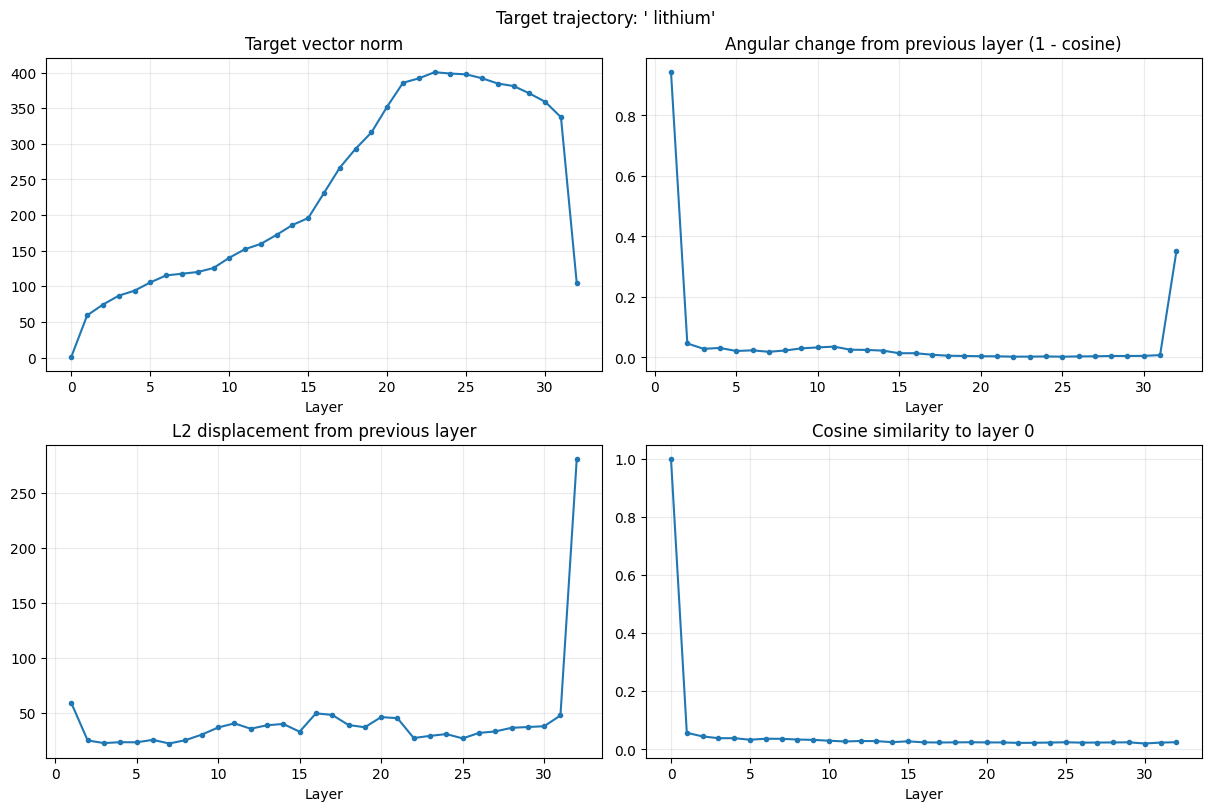

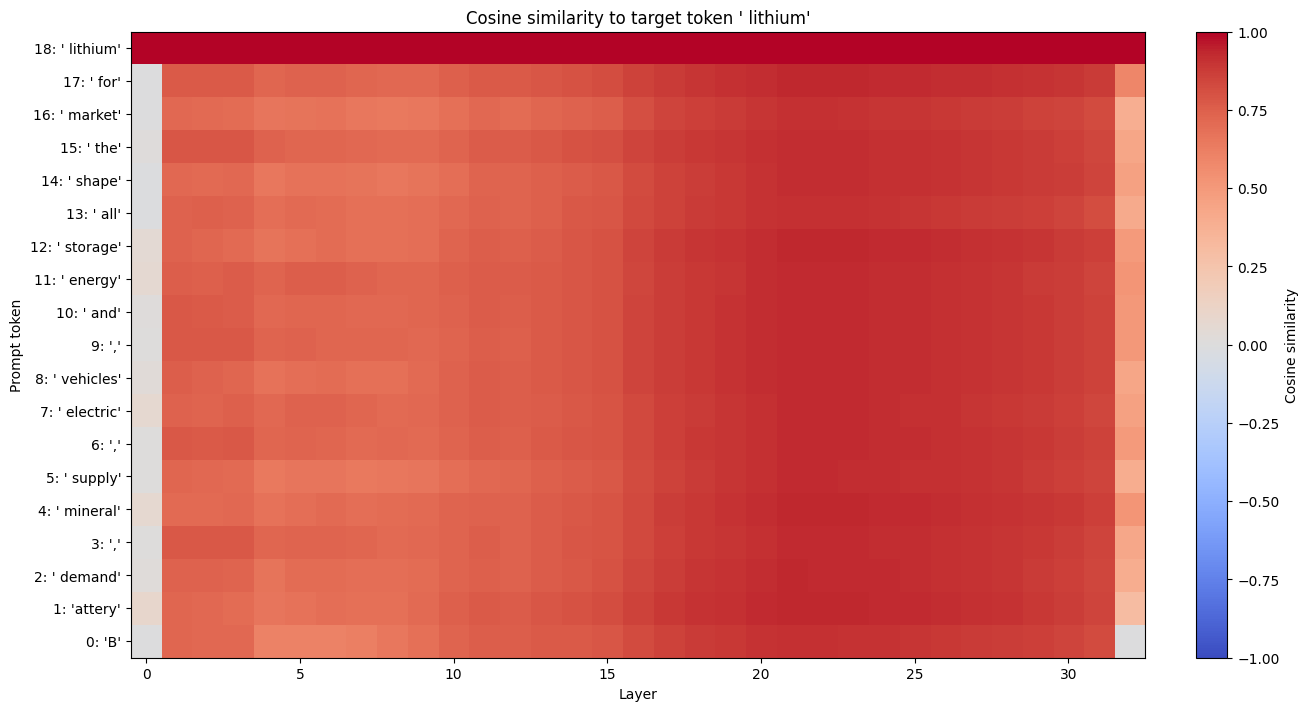

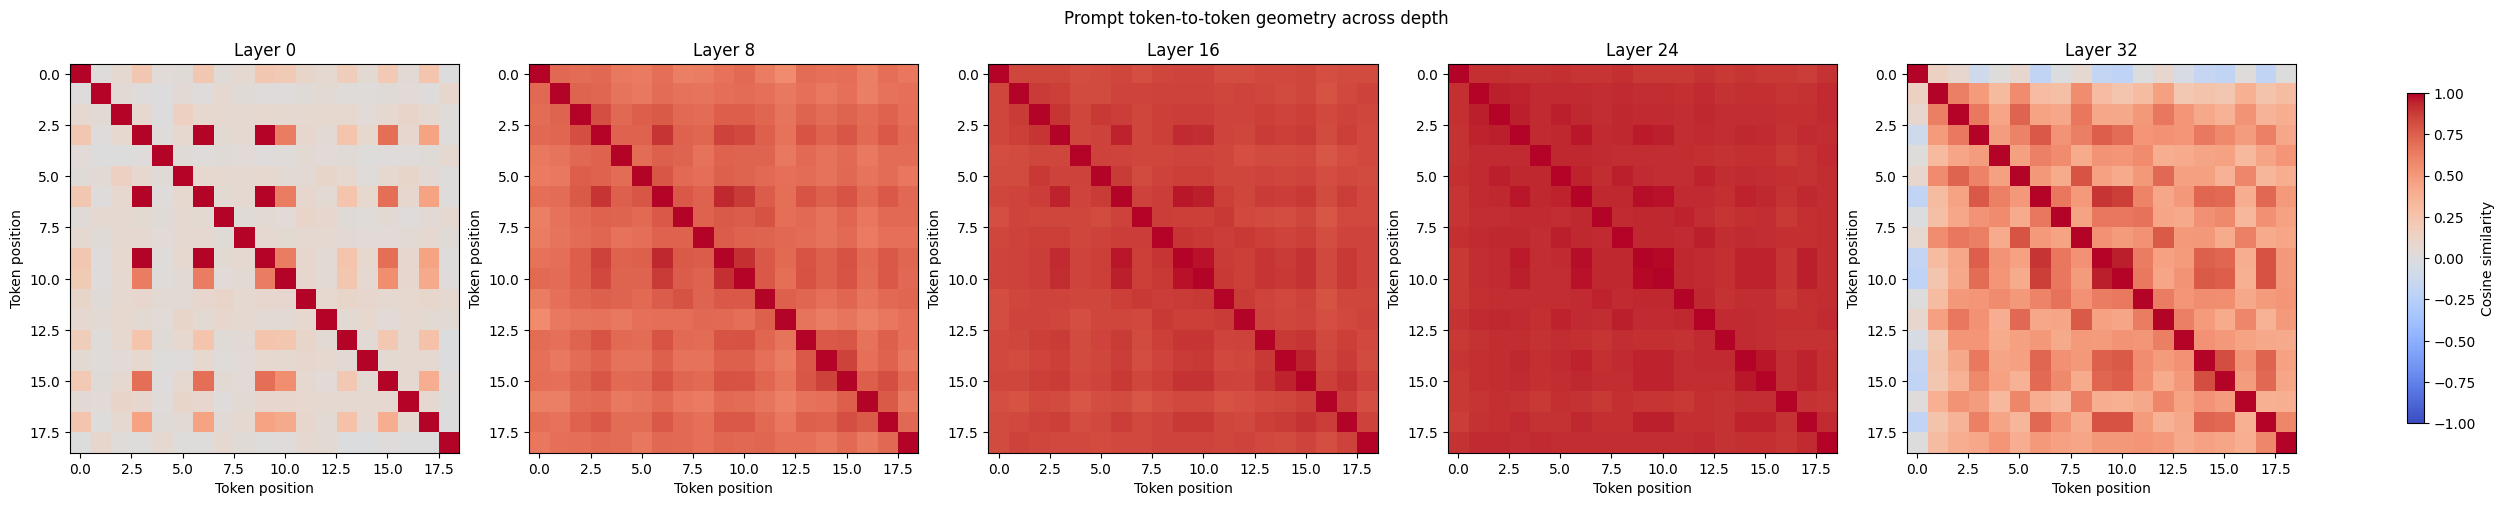

Run status:                    successful
Largest adjacent displacement: layer 32 (L2=280.995)
Lowest similarity to input:    layer 30 (cosine=0.0203)
Analysis elapsed:              3.544 seconds


,layer,relative_depth,norm,cosine_previous,angular_change,l2_previous,cosine_input,l2_input
0,0,0.00000,1.185632,NaN,NaN,NaN,1.000001,0.000000
1,1,0.03125,59.193016,0.057075,0.942925,59.137222,0.057075,59.137222
2,2,0.06250,74.295395,0.953859,0.046141,25.177826,0.044790,74.251747
3,3,0.09375,86.786789,0.971802,0.028198,22.796261,0.038530,86.749214
4,4,0.12500,93.818619,0.968825,0.031175,23.603563,0.038605,93.780365
5,5,0.15625,105.424973,0.978911,0.021089,23.492224,0.033301,105.392174
6,6,0.18750,115.240997,0.976727,0.023273,25.726839,0.036715,115.203590
7,7,0.21875,117.591812,0.981674,0.018326,22.410244,0.036405,117.554649
8,8,0.25000,120.001793,0.977270,0.022730,25.442471,0.033928,119.967445
9,9,0.28125,125.631668,0.970205,0.029795,30.497532,0.032790,125.598419


,layer,relative_depth,target_position,other_position,other_token_id,other_token,cosine_similarity
0,0,0.0,18,0,35,B,-0.000727
1,0,0.0,18,1,27263,attery,0.091902
2,0,0.0,18,2,4831,demand,0.016712
3,0,0.0,18,3,13,",",0.001745
4,0,0.0,18,4,17160,mineral,0.064597
...,...,...,...,...,...,...,...
622,32,1.0,18,14,5281,shape,0.458374
623,32,1.0,18,15,253,the,0.434478
624,32,1.0,18,16,2791,market,0.385743
625,32,1.0,18,17,323,for,0.589191


,source,metric,rank,token_id,raw_token,decoded_token,score
0,input_embedding,cosine_similarity,1,8182,ĠLi,Li,0.249577
1,input_embedding,cosine_similarity,2,17448,Li,Li,0.210541
2,input_embedding,cosine_similarity,3,31976,ĠLith,Lith,0.194067
3,input_embedding,cosine_similarity,4,23160,Ġpotassium,potassium,0.177643
4,input_embedding,cosine_similarity,5,29742,Ġmagnesium,magnesium,0.175821
5,input_embedding,cosine_similarity,6,46456,Ġcobalt,cobalt,0.170346
6,input_embedding,cosine_similarity,7,38244,Ġhelium,helium,0.162746
7,input_embedding,cosine_similarity,8,11914,Ġsodium,sodium,0.157767
8,input_embedding,cosine_similarity,9,20837,assium,assium,0.152253
9,input_embedding,cosine_similarity,10,26796,odium,odium,0.149099


In [3]:
analysis_started = time.perf_counter()
try:
    saved_tensors = load_file(HIDDEN_STATES_PATH, device="cpu")
    states = saved_tensors["hidden_states"].float()
    if not torch.isfinite(states).all():
        raise RuntimeError("Saved hidden states contain NaN or infinite values.")
    expected_shape = tuple(manifest["capture"]["hidden_state_shape"])
    if tuple(states.shape) != expected_shape:
        raise RuntimeError(
            f"Saved shape {tuple(states.shape)} does not match manifest {expected_shape}."
        )

    token_table = pd.read_csv(TOKENS_PATH)
    semantic_neighbors = pd.read_csv(SEMANTIC_NEIGHBORS_PATH)
    target_position = int(manifest["input"]["target_position"])
    layer_count, token_count, hidden_dimension = states.shape
    normalized_states = F.normalize(states, dim=-1)
    target_states = states[:, target_position, :]
    normalized_targets = normalized_states[:, target_position, :]
    input_target = target_states[0]

    metric_rows = []
    for layer in range(layer_count):
        current = target_states[layer]
        if layer == 0:
            cosine_previous = None
            l2_previous = None
        else:
            previous = target_states[layer - 1]
            cosine_previous = float(
                F.cosine_similarity(current, previous, dim=0).item()
            )
            l2_previous = float(torch.dist(current, previous, p=2).item())
        metric_rows.append(
            {
                "layer": layer,
                "relative_depth": layer / (layer_count - 1),
                "norm": float(torch.linalg.vector_norm(current).item()),
                "cosine_previous": cosine_previous,
                "angular_change": (
                    None if cosine_previous is None else 1.0 - cosine_previous
                ),
                "l2_previous": l2_previous,
                "cosine_input": float(
                    F.cosine_similarity(current, input_target, dim=0).item()
                ),
                "l2_input": float(torch.dist(current, input_target, p=2).item()),
            }
        )
    layer_metrics = pd.DataFrame(metric_rows)
    layer_metrics.to_csv(LAYER_METRICS_PATH, index=False, encoding="utf-8")

    target_relationship_matrix = torch.einsum(
        "ld,ltd->lt",
        normalized_targets,
        normalized_states,
    )
    relationship_rows = []
    for layer in range(layer_count):
        for position in range(token_count):
            relationship_rows.append(
                {
                    "layer": layer,
                    "relative_depth": layer / (layer_count - 1),
                    "target_position": target_position,
                    "other_position": position,
                    "other_token_id": int(token_table.loc[position, "token_id"]),
                    "other_token": token_table.loc[position, "decoded_token"],
                    "cosine_similarity": float(
                        target_relationship_matrix[layer, position].item()
                    ),
                }
            )
    target_relationships = pd.DataFrame(relationship_rows)
    target_relationships.to_csv(
        TARGET_RELATIONSHIPS_PATH,
        index=False,
        encoding="utf-8",
    )

    figure_path = FIGURES_DIR / "target_trajectory.png"
    figure, axes = plt.subplots(2, 2, figsize=(12, 8), constrained_layout=True)
    axes[0, 0].plot(layer_metrics["layer"], layer_metrics["norm"], marker="o", markersize=3)
    axes[0, 0].set_title("Target vector norm")
    axes[0, 1].plot(layer_metrics["layer"], layer_metrics["angular_change"], marker="o", markersize=3)
    axes[0, 1].set_title("Angular change from previous layer (1 - cosine)")
    axes[1, 0].plot(layer_metrics["layer"], layer_metrics["l2_previous"], marker="o", markersize=3)
    axes[1, 0].set_title("L2 displacement from previous layer")
    axes[1, 1].plot(layer_metrics["layer"], layer_metrics["cosine_input"], marker="o", markersize=3)
    axes[1, 1].set_title("Cosine similarity to layer 0")
    for axis in axes.flat:
        axis.set_xlabel("Layer")
        axis.grid(alpha=0.25)
    figure.suptitle(f"Target trajectory: {TARGET_TEXT!r}")
    figure.savefig(figure_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)

    relationship_figure_path = FIGURES_DIR / "target_relationships.png"
    figure, axis = plt.subplots(figsize=(13, 7), constrained_layout=True)
    image = axis.imshow(
        target_relationship_matrix.T.numpy(),
        aspect="auto",
        origin="lower",
        cmap="coolwarm",
        vmin=-1.0,
        vmax=1.0,
    )
    token_labels = [
        f"{position}: {token_table.loc[position, 'decoded_token']!r}"
        for position in range(token_count)
    ]
    axis.set_yticks(range(token_count), labels=token_labels)
    axis.set_xlabel("Layer")
    axis.set_ylabel("Prompt token")
    axis.set_title(f"Cosine similarity to target token {TARGET_TEXT!r}")
    figure.colorbar(image, ax=axis, label="Cosine similarity")
    figure.savefig(relationship_figure_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)

    final_layer = layer_count - 1
    selected_layers = sorted(
        set([0, final_layer // 4, final_layer // 2, 3 * final_layer // 4, final_layer])
    )
    similarity_figure_path = FIGURES_DIR / "token_similarity_layers.png"
    figure, axes = plt.subplots(
        1,
        len(selected_layers),
        figsize=(5 * len(selected_layers), 5),
        constrained_layout=True,
    )
    if len(selected_layers) == 1:
        axes = [axes]
    for axis, layer in zip(axes, selected_layers):
        similarity = normalized_states[layer] @ normalized_states[layer].T
        image = axis.imshow(
            similarity.numpy(),
            cmap="coolwarm",
            vmin=-1.0,
            vmax=1.0,
        )
        axis.set_title(f"Layer {layer}")
        axis.set_xlabel("Token position")
        axis.set_ylabel("Token position")
    figure.colorbar(image, ax=list(axes), shrink=0.75, label="Cosine similarity")
    figure.suptitle("Prompt token-to-token geometry across depth")
    figure.savefig(similarity_figure_path, dpi=160, bbox_inches="tight")
    plt.show()
    plt.close(figure)

    artifact_paths = [
        TOKENS_PATH,
        HIDDEN_STATES_PATH,
        LAYER_METRICS_PATH,
        TARGET_RELATIONSHIPS_PATH,
        SEMANTIC_NEIGHBORS_PATH,
        figure_path,
        relationship_figure_path,
        similarity_figure_path,
    ]
    manifest["artifacts"] = {
        str(path.relative_to(RUN_DIR)).replace("\\", "/"): {
            "bytes": path.stat().st_size,
            "sha256": sha256_file(path),
        }
        for path in artifact_paths
    }
    manifest["analysis"] = {
        "selected_layers": selected_layers,
        "layer_count": layer_count,
        "token_count": token_count,
        "hidden_dimension": hidden_dimension,
    }
    manifest["components"]["analysis"] = {
        "status": "successful",
        "completed_at": utc_now_iso(),
    }
    manifest["status"] = "successful"
    manifest["completed_at"] = utc_now_iso()
    write_manifest()

    valid_changes = layer_metrics.dropna(subset=["l2_previous"])
    largest_change = valid_changes.loc[valid_changes["l2_previous"].idxmax()]
    lowest_input_similarity = layer_metrics.loc[layer_metrics["cosine_input"].idxmin()]
    print(f"Run status:                    {manifest['status']}")
    print(f"Largest adjacent displacement: layer {int(largest_change['layer'])} "
          f"(L2={largest_change['l2_previous']:.3f})")
    print(f"Lowest similarity to input:    layer {int(lowest_input_similarity['layer'])} "
          f"(cosine={lowest_input_similarity['cosine_input']:.4f})")
    print(f"Analysis elapsed:              {time.perf_counter() - analysis_started:.3f} seconds")
    display(layer_metrics)
    display(target_relationships)
    display(semantic_neighbors)
except Exception as error:
    mark_failed("analysis", error)
    raise

## Interpretation boundary

This run measures one prompt in one model. Layer-wise movement and cosine similarity are descriptive evidence, not proof of a topic, a causal mechanism, or a generally optimal layer. The static input neighbours, contextual hidden states and final predictions answer different questions and should not be ranked as if their scores were directly comparable.